In [1]:
import random
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import Subset

In [2]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

eval_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=eval_transform
)

100%|██████████| 170M/170M [11:59<00:00, 237kB/s] 


In [3]:
# Generate a random subset of CIFAR10 dataset with only 1000 images
generator = torch.Generator().manual_seed(42)
indices = torch.randperm(len(train_dataset), generator=generator)

train_indices = indices[:800]
val_indices = indices[800:1000]

train_data = Subset(train_dataset, train_indices)
val_data = Subset(eval_dataset, val_indices)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))

Training images: 800
Validation images: 200


In [5]:
# Load one image without a transform for the pipeline tests
raw_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False
)

image, _ = raw_dataset[0]

In [6]:
def to_displayable(tensor):
    """Undo ImageNet normalization so the tensor can be shown as an image."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    unnormalized = tensor * std + mean
    return unnormalized.clamp(0, 1).permute(1, 2, 0).numpy()

random.seed(0)
torch.manual_seed(0)
train_passes = [train_transform(image) for _ in range(5)]

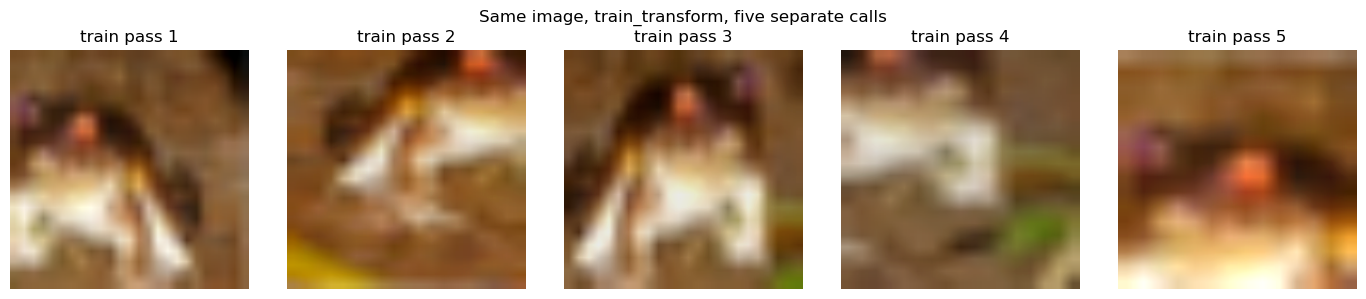

Output tensor shape (each pass): (3, 224, 224)


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for i, (ax, t) in enumerate(zip(axes, train_passes)):
    ax.imshow(to_displayable(t))
    ax.set_title(f"train pass {i + 1}")
    ax.axis("off")
fig.suptitle("Same image, train_transform, five separate calls")
plt.tight_layout()
plt.show()

print("Output tensor shape (each pass):", tuple(train_passes[0].shape))

In [8]:
# Confirm the five outputs are actually different from each other, not just
# visually similar: compare every pair of the five tensors directly.
all_different = True
for i in range(len(train_passes)):
    for j in range(i + 1, len(train_passes)):
        if torch.equal(train_passes[i], train_passes[j]):
            all_different = False
            print(f"pass {i + 1} and pass {j + 1} are identical (unexpected)")
assert all_different
print("Confirmed: all 5 training-pipeline outputs are pairwise different.")
print("Same source image, same pipeline, five genuinely different training examples.")

Confirmed: all 5 training-pipeline outputs are pairwise different.
Same source image, same pipeline, five genuinely different training examples.


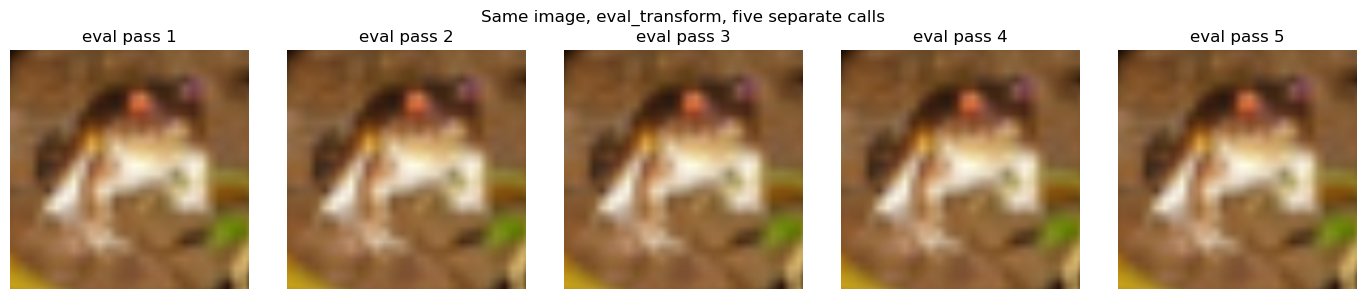

In [9]:
eval_passes = [eval_transform(image) for _ in range(5)]

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for i, (ax, t) in enumerate(zip(axes, eval_passes)):
    ax.imshow(to_displayable(t))
    ax.set_title(f"eval pass {i + 1}")
    ax.axis("off")
fig.suptitle("Same image, eval_transform, five separate calls")
plt.tight_layout()
plt.show()

In [10]:
all_identical = all(torch.equal(eval_passes[0], t) for t in eval_passes[1:])
assert all_identical
print("Confirmed: all 5 evaluation-pipeline outputs are exactly identical.")
print("This is the point of eval_transform: a fixed, reproducible view of")
print("each image, so a validation or test score means the same thing every")
print("time you compute it.")

Confirmed: all 5 evaluation-pipeline outputs are exactly identical.
This is the point of eval_transform: a fixed, reproducible view of
each image, so a validation or test score means the same thing every
time you compute it.
